# 02 – Huấn luyện FashionMNIST
Quy trình: DataLoader → mô hình → loss/optimizer → huấn luyện (Forward → Loss → Backward → Optimize) → đánh giá → vẽ Loss → lưu và tải lại mô hình.

Chạy từ thư mục `notebooks/`. Lần đầu `download=True` sẽ tải dữ liệu vào `data/input/`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))  # để import được src.*

import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter

from src.config import (BATCH_SIZE, LEARNING_RATE, EPOCHS, RANDOM_SEED, CLASS_NAMES,
                        NUM_CLASSES, TENSORBOARD_DIR, TABLES_DIR, CHECKPOINT_DIR,
                        ensure_dirs, set_seed, get_device)
from src.preprocessing.dataset import get_data_loaders
from src.models.neural_network import CNN
from src.models.model_io import save_model, load_model
from src.training.trainer import fit
from src.evaluation.metrics import evaluate, predict_all

ensure_dirs()
set_seed(RANDOM_SEED)
device = get_device()
print('device:', device)

device: cpu


## 1. Dữ liệu
`get_data_loaders` tải FashionMNIST (nếu chưa có), áp dụng transform và chia batch.

In [2]:
train_loader, test_loader = get_data_loaders(batch_size=BATCH_SIZE)
images, labels = next(iter(train_loader))
print('batch ảnh :', tuple(images.shape))   # kỳ vọng (64, 1, 28, 28)
print('batch nhãn:', tuple(labels.shape))   # kỳ vọng (64,)
print('số mẫu train / test:', len(train_loader.dataset), '/', len(test_loader.dataset))
print('pixel min/max sau Normalize:', images.min().item(), images.max().item())  # kỳ vọng ~[-1, 1]

batch ảnh : (64, 1, 28, 28)
batch nhãn: (64,)
số mẫu train / test: 60000 / 10000
pixel min/max sau Normalize: -1.0 1.0


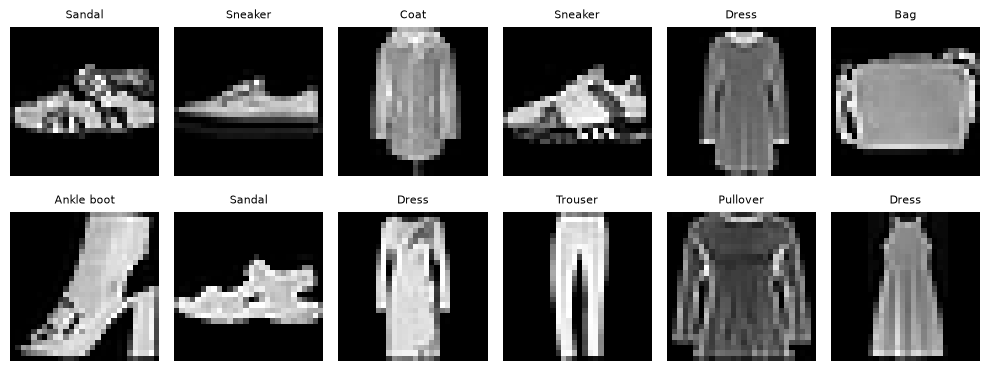

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap='gray'); ax.set_title(CLASS_NAMES[lab], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Mô hình, loss function, optimizer
Mô hình trả logits (không có Softmax) nên dùng `CrossEntropyLoss`, vì hàm này đã gồm LogSoftmax. Cấu hình đang dùng là `CNN` + Adam.

In [4]:
model = CNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print('số tham số:', sum(p.numel() for p in model.parameters()))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
số tham số: 421642


## 3. Huấn luyện
Mỗi epoch: duyệt toàn bộ tập train theo Forward → Loss → Backward → Optimize, rồi đánh giá trên tập test. Log TensorBoard: `tensorboard --logdir data/output/tensorboard`.

In [5]:
writer = SummaryWriter(str(TENSORBOARD_DIR / 'cnn_run_01'))
history = fit(model, train_loader, test_loader, loss_fn, optimizer,
              epochs=EPOCHS, device=device, writer=writer)
writer.close()

epoch 1 | train_loss=0.4758 | train_accuracy=0.8287 | test_loss=0.3257 | test_accuracy=0.8835


epoch 2 | train_loss=0.3024 | train_accuracy=0.8901 | test_loss=0.2945 | test_accuracy=0.8918


epoch 3 | train_loss=0.2539 | train_accuracy=0.9068 | test_loss=0.2617 | test_accuracy=0.9053


epoch 4 | train_loss=0.2245 | train_accuracy=0.9173 | test_loss=0.2390 | test_accuracy=0.9132


epoch 5 | train_loss=0.2000 | train_accuracy=0.9270 | test_loss=0.2353 | test_accuracy=0.9116


epoch 6 | train_loss=0.1795 | train_accuracy=0.9335 | test_loss=0.2382 | test_accuracy=0.9174


epoch 7 | train_loss=0.1622 | train_accuracy=0.9399 | test_loss=0.2326 | test_accuracy=0.9216


epoch 8 | train_loss=0.1461 | train_accuracy=0.9448 | test_loss=0.2362 | test_accuracy=0.9209


epoch 9 | train_loss=0.1321 | train_accuracy=0.9508 | test_loss=0.2419 | test_accuracy=0.9169


epoch 10 | train_loss=0.1182 | train_accuracy=0.9560 | test_loss=0.2524 | test_accuracy=0.9193


## 4. Đánh giá trên tập test

In [6]:
final = evaluate(model, test_loader, loss_fn, device)
print(f"test loss = {final['loss']:.4f} | test accuracy = {final['accuracy']:.4f}")

test loss = 0.2524 | test accuracy = 0.9193


Bảng precision / recall / F1 theo lớp và confusion matrix. Tính trực tiếp bằng tensor nên không cần thêm scikit-learn.

In [7]:
y_true, y_pred = predict_all(model, test_loader, device)
cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1          # hàng = nhãn thật, cột = nhãn dự đoán

tp = cm.diag().float()
precision = tp / cm.sum(dim=0).clamp(min=1)
recall = tp / cm.sum(dim=1).clamp(min=1)
f1 = 2 * precision * recall / (precision + recall).clamp(min=1e-12)
report = pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1,
                       'support': cm.sum(dim=1)}, index=CLASS_NAMES).round(4)
report.to_csv(TABLES_DIR / 'class_report.csv')
report

,precision,recall,f1,support
T-shirt/top,0.8492,0.867,0.8580,1000
Trouser,0.9890,0.988,0.9885,1000
Pullover,0.8733,0.903,0.8879,1000
Dress,0.9376,0.902,0.9195,1000
Coat,0.8962,0.855,0.8751,1000
Sandal,0.9840,0.985,0.9845,1000
Shirt,0.7542,0.767,0.7605,1000
Sneaker,0.9678,0.963,0.9654,1000
Bag,0.9783,0.990,0.9841,1000
Ankle boot,0.9682,0.973,0.9706,1000


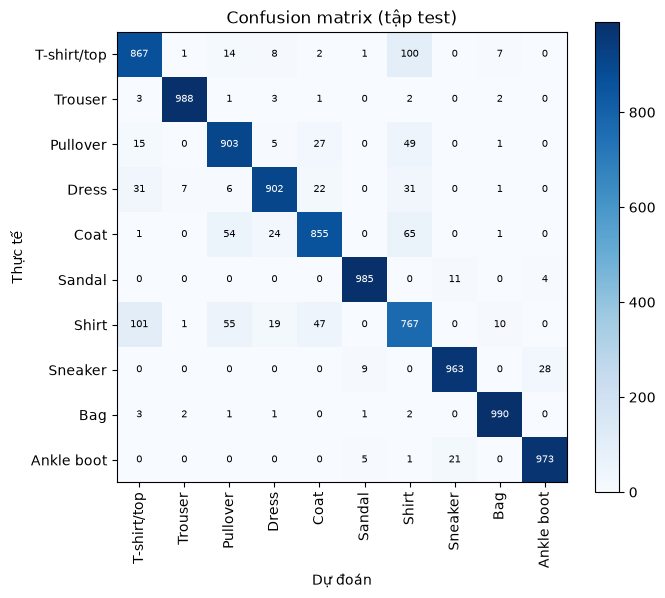

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=90)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set(xlabel='Dự đoán', ylabel='Thực tế', title='Confusion matrix (tập test)')
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=7,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im); plt.tight_layout(); plt.show()

## 5. Loss và Accuracy theo epoch
History được lưu ra CSV để Đức dùng khi vẽ biểu đồ cuối.

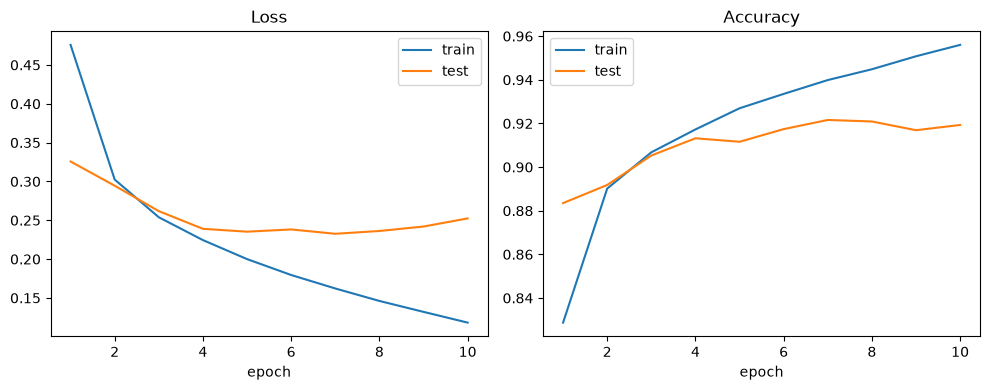

,epoch,train_loss,train_accuracy,test_loss,test_accuracy
0,1,0.475838,0.828733,0.325690,0.8835
1,2,0.302419,0.890150,0.294503,0.8918
2,3,0.253871,0.906767,0.261746,0.9053
3,4,0.224455,0.917250,0.238991,0.9132
4,5,0.199998,0.926950,0.235310,0.9116
5,6,0.179526,0.933533,0.238188,0.9174
6,7,0.162171,0.939883,0.232605,0.9216
7,8,0.146111,0.944833,0.236198,0.9209
8,9,0.132054,0.950783,0.241930,0.9169
9,10,0.118222,0.956000,0.252387,0.9193


In [9]:
df = pd.DataFrame(history)
df.to_csv(TABLES_DIR / 'training_history.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(df.epoch, df.train_loss, label='train'); ax[0].plot(df.epoch, df.test_loss, label='test')
ax[0].set(title='Loss', xlabel='epoch'); ax[0].legend()
ax[1].plot(df.epoch, df.train_accuracy, label='train'); ax[1].plot(df.epoch, df.test_accuracy, label='test')
ax[1].set(title='Accuracy', xlabel='epoch'); ax[1].legend()
plt.tight_layout(); plt.show()
df

## 6. Lưu mô hình và tải lại
Kiểm tra: mô hình tải lại phải cho đúng accuracy như trước khi lưu.

In [10]:
ckpt_path = save_model(model)   # mặc định: data/output/checkpoints/fashion_mnist_model.pth
print('đã lưu:', ckpt_path)

reloaded = load_model(CNN(), ckpt_path, device)
after = evaluate(reloaded, test_loader, loss_fn, device)
print('accuracy trước khi lưu :', final['accuracy'])
print('accuracy sau khi tải lại:', after['accuracy'])
assert abs(final['accuracy'] - after['accuracy']) < 1e-9, 'Accuracy lệch sau khi tải lại!'

đã lưu: /home/claude/Practice_1/data/output/checkpoints/fashion_mnist_model.pth


accuracy trước khi lưu : 0.9193
accuracy sau khi tải lại: 0.9193


## Ghi chú cho báo cáo
Điền số liệu thật vào `docs/06_results/evaluation_results.md` sau khi chạy: cấu hình, loss/accuracy cuối, các lớp bị nhầm nhiều (xem confusion matrix) và khoảng cách train–test.